In [1]:
# https://www.kaggle.com/datasets/mursideyarkin/mobile-games-ab-testing-cookie-cats
# Column	           Description
# userid	           Unique player ID
# version	           Which group the player was in: gate_30 (control) or gate_40 (treatment)
# sum_gamerounds	   Number of game rounds played in the first 14 days after install
# retention_1	       Boolean — did the player come back 1 day after installing?
# retention_7	       Boolean — did the player come back 7 days after installing?

# The actual business question you're testing:
# Does delaying the first gate from level 30 to level 40 hurt or help player retention? 
# (Tactile's real hypothesis was that more gameplay before the first paywall would increase engagement — 
# but you'll find the data says something more nuanced.)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


In [3]:
df=pd.read_csv("../data/cookie_cats.csv")

In [4]:
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [5]:
df.dtypes

userid            int64
version             str
sum_gamerounds    int64
retention_1        bool
retention_7        bool
dtype: object

In [6]:
df.isnull().sum()

userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

In [7]:
# df.duplicated() is a Pandas method that identifies duplicate rows in a DataFrame.

# Syntax
# df.duplicated(subset=None, keep='first')
# Parameters
# subset: Column name(s) to consider when checking duplicates.
# keep:
# 'first' (default): Marks all duplicates except the first occurrence as True.
# 'last': Marks all duplicates except the last occurrence as True.
# False: Marks all duplicate rows as True.

# Check duplicates based on a specific column
# df.duplicated(subset=['Name'])

# Show only duplicate rows
# df[df.duplicated()]

# Count duplicate rows
# df.duplicated().sum()

# Mark all duplicate occurrences
# df.duplicated(keep=False)

# Output:
# 0     True
# 1    False
# 2     True
# 3    False
# dtype: bool

# Remove duplicates
# df.drop_duplicates()

# or based on a specific column:
# df.drop_duplicates(subset=['Name'], keep='first')

# duplicated() only identifies duplicate rows (returns a Boolean Series); 
# it does not remove them. Use drop_duplicates() to remove duplicates.
# import pandas as pd

# check = pd.DataFrame({
#     'Name': ['Alice', 'Bob', 'Alice', 'Charlie'],
#     'Age': [25, 30, 25, 35]
# })

# print(check.duplicated(keep='last'))

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   userid          90189 non-null  int64
 1   version         90189 non-null  str  
 2   sum_gamerounds  90189 non-null  int64
 3   retention_1     90189 non-null  bool 
 4   retention_7     90189 non-null  bool 
dtypes: bool(2), int64(2), str(1)
memory usage: 2.8 MB


In [10]:
pd.api.types.is_numeric_dtype(df['userid']) #Check whether a column has the expected datatype

True

<Axes: xlabel='version'>

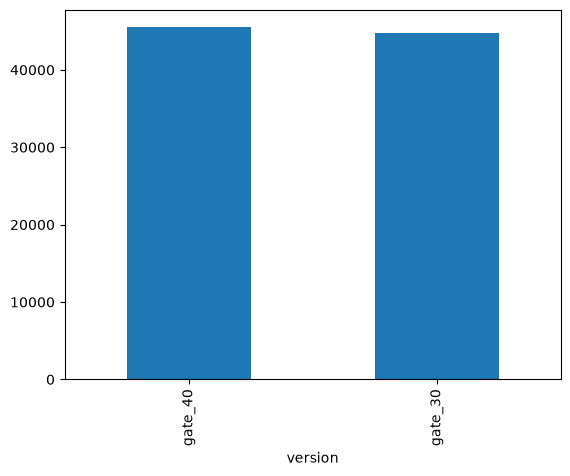

In [11]:
df.version.value_counts().plot(kind='bar')

In [12]:
df.sum_gamerounds.describe()

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

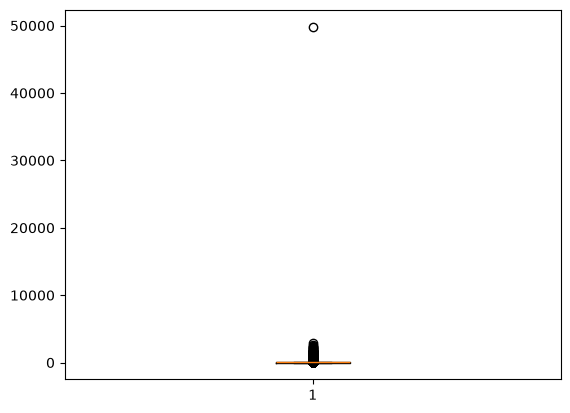

In [13]:
plt.boxplot(df['sum_gamerounds'])
plt.show()

In [14]:
Q1 = df['sum_gamerounds'].quantile(0.25)
Q3 = df['sum_gamerounds'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['sum_gamerounds'] < lower_bound) | (df['sum_gamerounds'] > upper_bound)]

print("Number of outliers:", len(outliers))
# we can't use IQR method to check for the outliers because it will consider all points less than 25% and greater than 75% as a outlier which would be true if we are dealing with perfectly normal distribution but here the data is heavily right skewed so we can't use this method to remove outliers

Number of outliers: 10177


<Axes: ylabel='Density'>

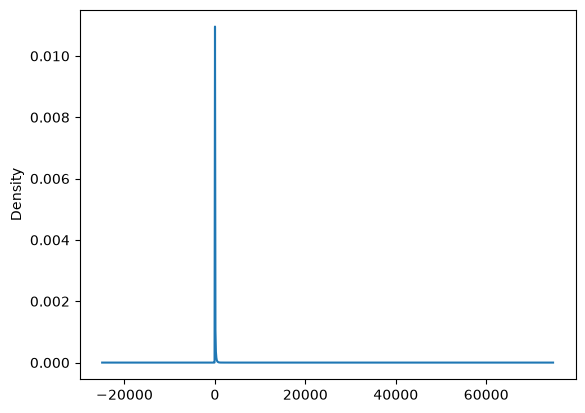

In [15]:
df['sum_gamerounds'].plot(kind='kde')

Counts: [90188     0     0     0     1]
Bin edges: [    0.   9970.8 19941.6 29912.4 39883.2 49854. ]


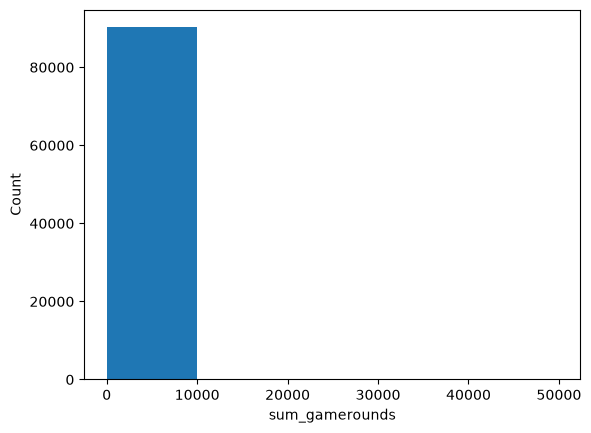

In [16]:
counts, bin_edges = np.histogram(df['sum_gamerounds'], bins=5)

print("Counts:", counts)
print("Bin edges:", bin_edges)

width = bin_edges[1] - bin_edges[0]

plt.bar(
    bin_edges[:-1],
    counts,
    width=width,
    align='edge'
)

plt.xlabel('sum_gamerounds')
plt.ylabel('Count')
plt.show()

In [17]:
df.drop(df[df['sum_gamerounds'] == 49854].index, inplace=True)

In [18]:
counts, bin_edges = np.histogram(df['sum_gamerounds'], bins=10)

print("Counts:", counts)
print("Bin edges:", bin_edges)

Counts: [87446  2212   376    88    39    16     4     4     2     1]
Bin edges: [   0.   296.1  592.2  888.3 1184.4 1480.5 1776.6 2072.7 2368.8 2664.9
 2961. ]


In [19]:
# Don't remove any more points. Treat the remaining tail as real signal, not noise.
# Visualize on a log scale — plot sum_gamerounds histogram with a log x-axis (or log-transform the values first). This will turn the distribution into something closer to interpretable shape instead of one giant bar, and is the standard way to visualize this kind of skewed count data.

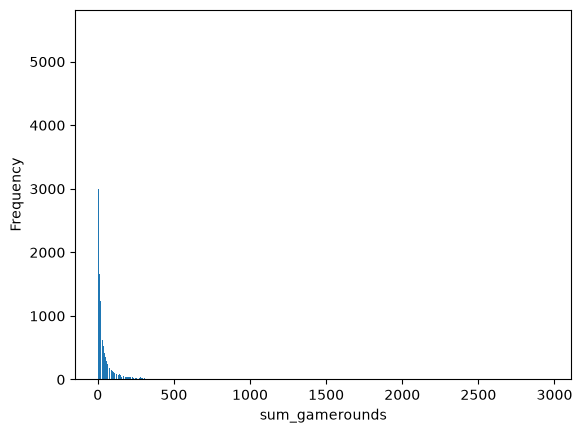

In [20]:
counts = df['sum_gamerounds'].value_counts().sort_index()

plt.bar(counts.index, counts.values)

plt.xlabel('sum_gamerounds')
plt.ylabel('Frequency')
plt.show()
# this graph count occurence of each number using value counts and then make a graph the benefit of using this is graph looks more smoother unlike bar graph which have fixed sized bins here there is no concept of bins just it counts occurence of each values

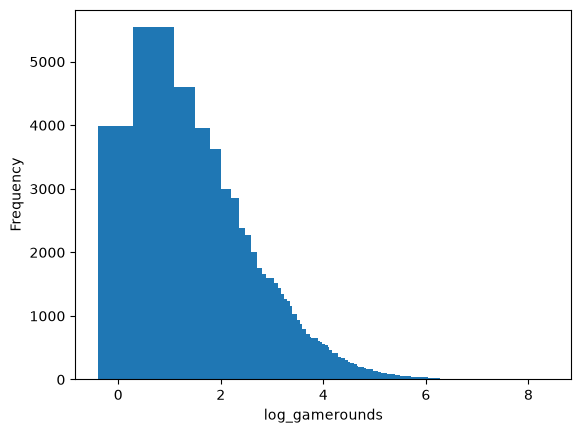

In [21]:
# Log transformation is often a good choice for a heavily right-skewed variable
df['log_gamerounds'] = np.log1p(df['sum_gamerounds'])

counts = df['log_gamerounds'].value_counts().sort_index()

plt.bar(counts.index, counts.values)

plt.xlabel('log_gamerounds')
plt.ylabel('Frequency')
plt.show()

<Axes: ylabel='Density'>

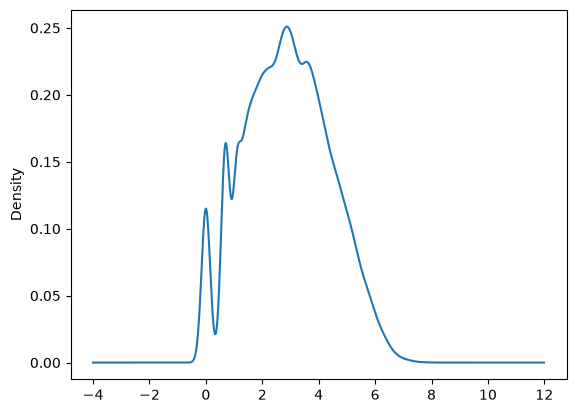

In [22]:
df['log_gamerounds'].plot(kind='kde')

In [23]:
df['log_gamerounds'].describe()

count    90188.000000
mean         2.879658
std          1.503568
min          0.000000
25%          1.791759
50%          2.833213
75%          3.951244
max          7.993620
Name: log_gamerounds, dtype: float64

In [24]:
# Check retention rates (retention_1, retention_7)
df.columns
df['retention_1'].value_counts()
df['retention_7'].value_counts()

retention_7
False    73408
True     16780
Name: count, dtype: int64

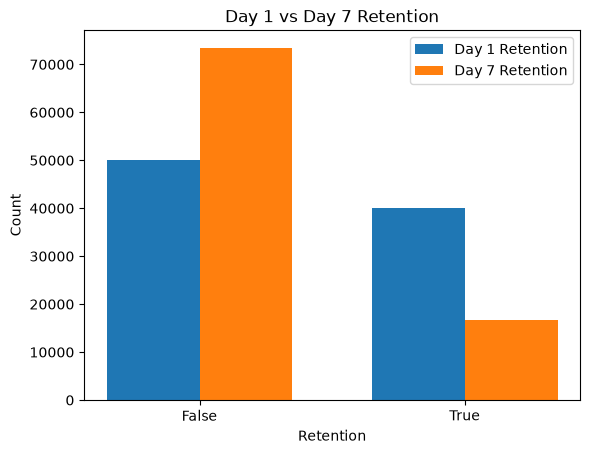

In [25]:
import matplotlib.pyplot as plt

retention_1 = df['retention_1'].value_counts().sort_index()
retention_7 = df['retention_7'].value_counts().sort_index()

x = range(len(retention_1))
width = 0.35

plt.bar([i - width/2 for i in x], retention_1.values,
        width=width, label='Day 1 Retention')

plt.bar([i + width/2 for i in x], retention_7.values,
        width=width, label='Day 7 Retention')

plt.xticks(x, retention_1.index)
plt.xlabel('Retention')
plt.ylabel('Count')
plt.title('Day 1 vs Day 7 Retention')
plt.legend()

plt.show()


In [26]:
# Step 10: Sample Ratio Mismatch (SRM) Check
df.columns

Index(['userid', 'version', 'sum_gamerounds', 'retention_1', 'retention_7',
       'log_gamerounds'],
      dtype='str')

In [35]:
gate_count = df['version'].value_counts().reset_index()

gate_count['expected_count'] = len(df['version']) / 2
gate_count['actual-expected']=abs(gate_count['expected_count']-gate_count['count'])
gate_count

,version,count,expected_count,actual-expected
0,gate_40,45489,45094.0,395.0
1,gate_30,44699,45094.0,395.0


In [36]:
from scipy.stats import chisquare

observed = df['version'].value_counts()

chisquare(observed)

Power_divergenceResult(statistic=np.float64(6.919989355568369), pvalue=np.float64(0.008523748341090839))

In [41]:
df.duplicated(subset=['userid']).value_counts()
# checked for duplicate/missing userids and found none (assuming that's true once you check)

False    90188
Name: count, dtype: int64

### Phase 4: Hypothesis Formulation

In [ ]:
# H0: retention_1 is equal between gate_30 and gate_40
# H1: retention_1 is not equal between gate_30 and gate_40
# significance level (α, 0.05)

### Phase 5: Statistical Testing

In [43]:
# 14. Test 1-day retention: run a two-proportion z-test (or chi-square test) comparing retention_1 between groups
from statsmodels.stats.proportion import proportions_ztest

# Number of retained users in each group
success = df.groupby('version')['retention_1'].sum()

# Total users in each group
nobs = df.groupby('version')['retention_1'].count()

# Two-proportion z-test
z_stat, p_value = proportions_ztest(
    count=success,
    nobs=nobs
)

print("Z-statistic:", z_stat)
print("p-value:", p_value)

Z-statistic: 1.787103509763628
p-value: 0.0739207603418346


In [44]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0: Significant difference in 1-day retention.")
else:
    print("Fail to reject H0: No significant difference in 1-day retention.")

Fail to reject H0: No significant difference in 1-day retention.


In [45]:
# 15. Test 7-day retention: run the same test for retention_7

# Number of retained users in each group
success = df.groupby('version')['retention_7'].sum()

# Total users in each group
nobs = df.groupby('version')['retention_7'].count()

# Two-proportion z-test
z_stat, p_value = proportions_ztest(
    count=success,
    nobs=nobs
)

print("Z-statistic:", z_stat)
print("p-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0: Significant difference in 1-day retention.")
else:
    print("Fail to reject H0: No significant difference in 1-day retention.")

Z-statistic: 3.1574100858819936
p-value: 0.0015917731773993442
Reject H0: Significant difference in 1-day retention.


#### Check normality with Shapiro-Wilk

In [47]:
from scipy.stats import shapiro

# Separate the two groups
control = df[df['version'] == 'gate_30']['sum_gamerounds']
treatment = df[df['version'] == 'gate_40']['sum_gamerounds']

# Shapiro-Wilk normality test
stat_control, p_control = shapiro(control)
stat_treatment, p_treatment = shapiro(treatment)

print("Control p-value:", p_control)
print("Treatment p-value:", p_treatment)

if p_control < 0.05 or p_treatment < 0.05:
    print("At least one group is non-normal → use Mann-Whitney U test")
else:
    print("Both groups appear normal → parametric test may be considered")

# Note: With very large datasets, Shapiro-Wilk will often reject normality even for relatively minor deviations. For this dataset, a histogram/KDE or Q-Q plot is also useful.

Control p-value: 2.36253070250176e-139
Treatment p-value: 3.3446548187520663e-140
At least one group is non-normal → use Mann-Whitney U test


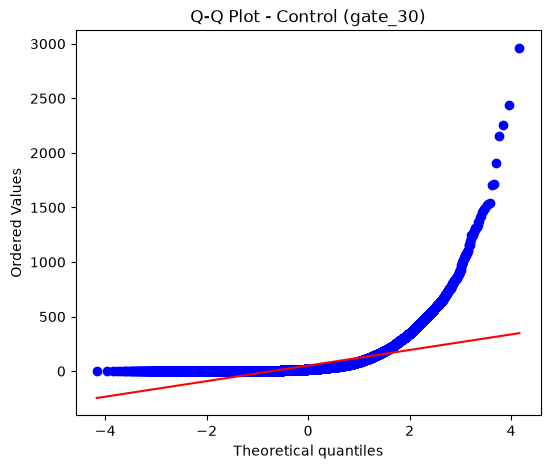

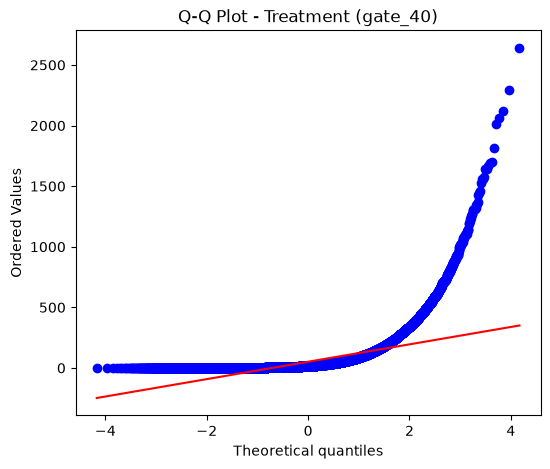

In [48]:
# Q-Q plot
import matplotlib.pyplot as plt
from scipy.stats import probplot

plt.figure(figsize=(6, 5))
probplot(control, dist="norm", plot=plt)
plt.title("Q-Q Plot - Control (gate_30)")
plt.show()

plt.figure(figsize=(6, 5))
probplot(treatment, dist="norm", plot=plt)
plt.title("Q-Q Plot - Treatment (gate_40)")
plt.show()
# points substantially deviate from the straight line, that supports the conclusion that the data are not normally distributed.

In [52]:
# compare the median rather than only the mean because the distribution is skewed:
print("Control median:", control.median())
print("Treatment median:", treatment.median())

print("Control mean:", control.mean())
print("Treatment mean:", treatment.mean())

Control median: 17.0
Treatment median: 16.0
Control mean: 51.342110561757536
Treatment mean: 51.29877552814966


In [51]:
# . Mann-Whitney U test

# Since sum_gamerounds is typically heavily right-skewed, this is a good choice:

from scipy.stats import mannwhitneyu

u_stat, p_value = mannwhitneyu(
    control,
    treatment,
    alternative='two-sided'
)

print("Mann-Whitney U statistic:", u_stat)
print("p-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0: Significant difference in engagement between groups.")
else:
    print("Fail to reject H0: No significant difference in engagement between groups.")

Mann-Whitney U statistic: 1024285761.5
p-value: 0.05089155279145376
Fail to reject H0: No significant difference in engagement between groups.


In [53]:
# 17. Calculate confidence intervals for the difference in proportions/means, not just p-values
import numpy as np
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.proportion import confint_proportions_2indep

control = df[df['version'] == 'gate_30']['retention_1']
treatment = df[df['version'] == 'gate_40']['retention_1']

# Number of retained users
success_control = control.sum()
success_treatment = treatment.sum()

# Number of users
n_control = len(control)
n_treatment = len(treatment)

# Retention proportions
p_control = success_control / n_control
p_treatment = success_treatment / n_treatment

# Difference: treatment - control
difference = p_treatment - p_control

# Two-proportion z-test
z_stat, p_value = proportions_ztest(
    [success_treatment, success_control],
    [n_treatment, n_control]
)

# 95% CI for difference in proportions
ci_low, ci_high = confint_proportions_2indep(
    success_treatment,
    n_treatment,
    success_control,
    n_control,
    method='wald'
)

print("Control retention:", p_control)
print("Treatment retention:", p_treatment)
print("Difference:", difference)
print("95% CI:", (ci_low, ci_high))
print("Z-statistic:", z_stat)
print("p-value:", p_value)
print(f"Control retention: {p_control:.2%}")
print(f"Treatment retention: {p_treatment:.2%}")
print(f"Difference: {difference:.2%}")
print(f"95% CI: ({ci_low:.2%}, {ci_high:.2%})")
print(f"p-value: {p_value:.4f}")

Control retention: 0.4481979462627799
Treatment retention: 0.44228274967574577
Difference: -0.005915196587034155
95% CI: (np.float64(-0.012402509778563666), np.float64(0.0005721166044953558))
Z-statistic: -1.787103509763628
p-value: 0.0739207603418346
Control retention: 44.82%
Treatment retention: 44.23%
Difference: -0.59%
95% CI: (-1.24%, 0.06%)
p-value: 0.0739


In [54]:
# 18. Calculate effect size (e.g., Cohen's h for proportions) alongside statistical significance
import numpy as np

# Retention rates
p_control = df[df['version'] == 'gate_30']['retention_1'].mean()
p_treatment = df[df['version'] == 'gate_40']['retention_1'].mean()

# Cohen's h
cohens_h = 2 * (
    np.arcsin(np.sqrt(p_treatment)) -
    np.arcsin(np.sqrt(p_control))
)

print("Control retention:", p_control)
print("Treatment retention:", p_treatment)
print("Cohen's h:", cohens_h)

abs_h = abs(cohens_h)

if abs_h < 0.2:
    effect = "Small/negligible effect"
elif abs_h < 0.5:
    effect = "Small to medium effect"
elif abs_h < 0.8:
    effect = "Medium to large effect"
else:
    effect = "Large effect"

print("Effect size:", effect)

Control retention: 0.4481979462627799
Treatment retention: 0.44228274967574577
Cohen's h: -0.011902060379805679
Effect size: Small/negligible effect


In [55]:
from statsmodels.stats.proportion import proportions_ztest

success_control = df[df['version'] == 'gate_30']['retention_1'].sum()
success_treatment = df[df['version'] == 'gate_40']['retention_1'].sum()

n_control = df[df['version'] == 'gate_30']['retention_1'].count()
n_treatment = df[df['version'] == 'gate_40']['retention_1'].count()

z_stat, p_value = proportions_ztest(
    [success_treatment, success_control],
    [n_treatment, n_control]
)

print("Z-statistic:", z_stat)
print("p-value:", p_value)
print("Cohen's h:", cohens_h)

Z-statistic: -1.787103509763628
p-value: 0.0739207603418346
Cohen's h: -0.011902060379805679


## Phase 6: Deeper Analysis

In [56]:
# 19. Run a bootstrap simulation (resample with replacement many times) to get a distribution of retention differences — cross-validates your z-test result and is a good "extra rigor" addition
import numpy as np
import matplotlib.pyplot as plt

# Separate the two groups
control = df[df['version'] == 'gate_30']['retention_1'].dropna().values
treatment = df[df['version'] == 'gate_40']['retention_1'].dropna().values

# Observed difference in retention
observed_diff = treatment.mean() - control.mean()

# Bootstrap
n_iterations = 10000
bootstrap_diffs = []

np.random.seed(42)

for _ in range(n_iterations):

    # Resample with replacement
    control_sample = np.random.choice(
        control,
        size=len(control),
        replace=True
    )

    treatment_sample = np.random.choice(
        treatment,
        size=len(treatment),
        replace=True
    )

    # Difference in retention
    diff = treatment_sample.mean() - control_sample.mean()

    bootstrap_diffs.append(diff)

bootstrap_diffs = np.array(bootstrap_diffs)

print("Observed difference:", observed_diff)

Observed difference: -0.005915196587034155


In [57]:
# Calculate the 95% bootstrap confidence interval
ci_low = np.percentile(bootstrap_diffs, 2.5)
ci_high = np.percentile(bootstrap_diffs, 97.5)

print(f"Observed difference: {observed_diff:.4f}")
print(f"95% Bootstrap CI: ({ci_low:.4f}, {ci_high:.4f})")

# display it as percentages:

print(f"Observed difference: {observed_diff:.2%}")
print(f"95% Bootstrap CI: ({ci_low:.2%}, {ci_high:.2%})")

Observed difference: -0.0059
95% Bootstrap CI: (-0.0125, 0.0005)
Observed difference: -0.59%
95% Bootstrap CI: (-1.25%, 0.05%)


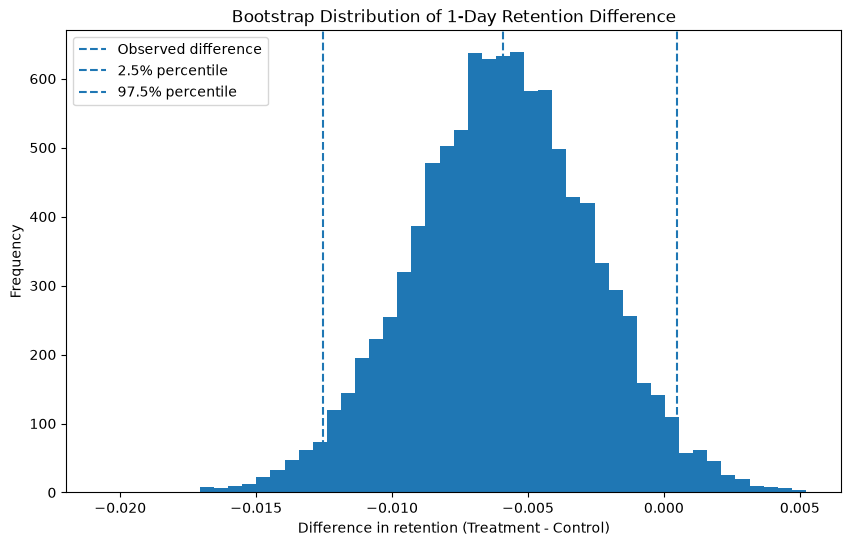

In [58]:
plt.figure(figsize=(10, 6))

plt.hist(bootstrap_diffs, bins=50)

plt.axvline(
    observed_diff,
    linestyle='--',
    label='Observed difference'
)

plt.axvline(
    ci_low,
    linestyle='--',
    label='2.5% percentile'
)

plt.axvline(
    ci_high,
    linestyle='--',
    label='97.5% percentile'
)

plt.xlabel('Difference in retention (Treatment - Control)')
plt.ylabel('Frequency')
plt.title('Bootstrap Distribution of 1-Day Retention Difference')
plt.legend()
plt.show()

In [59]:
# 20. Segment the analysis — e.g., does the effect differ for high-engagement vs low-engagement players (using sum_gamerounds as a segment)
median_rounds = df['sum_gamerounds'].median()

df['engagement_segment'] = np.where(
    df['sum_gamerounds'] <= median_rounds,
    'Low Engagement',
    'High Engagement'
)

print(df['engagement_segment'].value_counts())

engagement_segment
Low Engagement     45114
High Engagement    45074
Name: count, dtype: int64


In [60]:
# Compare retention within each segment
from statsmodels.stats.proportion import proportions_ztest

for segment in ['Low Engagement', 'High Engagement']:

    data = df[df['engagement_segment'] == segment]

    control = data[data['version'] == 'gate_30']['retention_1']
    treatment = data[data['version'] == 'gate_40']['retention_1']

    success = [
        treatment.sum(),
        control.sum()
    ]

    nobs = [
        len(treatment),
        len(control)
    ]

    z_stat, p_value = proportions_ztest(
        success,
        nobs
    )

    control_rate = control.mean()
    treatment_rate = treatment.mean()
    difference = treatment_rate - control_rate

    print(f"\n{segment}")
    print("-" * 30)
    print(f"Control retention:   {control_rate:.2%}")
    print(f"Treatment retention: {treatment_rate:.2%}")
    print(f"Difference:          {difference:.2%}")
    print(f"Z-statistic:         {z_stat:.3f}")
    print(f"P-value:             {p_value:.4f}")


Low Engagement
------------------------------
Control retention:   16.14%
Treatment retention: 16.15%
Difference:          0.02%
Z-statistic:         0.048
P-value:             0.9620

High Engagement
------------------------------
Control retention:   73.04%
Treatment retention: 72.80%
Difference:          -0.24%
Z-statistic:         -0.575
P-value:             0.5655


In [64]:
# 21. Consider a Bayesian A/B test as an alternative/complementary approach (e.g., using Beta-Binomial conjugate priors) to report probability that gate_30 beats gate_40, not just a p-value
# Since retention is binary (0/1), the Beta-Binomial model is a natural choice.

# 1. Set up Beta priors

# We'll use a weakly informative uniform prior:

# After observing the data:
import numpy as np

# Split groups
gate_30 = df[df['version'] == 'gate_30']['retention_1']
gate_40 = df[df['version'] == 'gate_40']['retention_1']

# Number of retained users
success_30 = gate_30.sum()
success_40 = gate_40.sum()

# Number of users who were not retained
failure_30 = len(gate_30) - success_30
failure_40 = len(gate_40) - success_40

# Beta(1,1) prior
alpha_prior = 1
beta_prior = 1

# Posterior parameters
alpha_30 = alpha_prior + success_30
beta_30 = beta_prior + failure_30

alpha_40 = alpha_prior + success_40
beta_40 = beta_prior + failure_40

print("gate_30 posterior:", alpha_30, beta_30)
print("gate_40 posterior:", alpha_40, beta_40)

gate_30 posterior: 20035 24666
gate_40 posterior: 20120 25371


In [65]:
# 2. Sample from the posterior distributions
np.random.seed(42)

n_samples = 100000

posterior_30 = np.random.beta(
    alpha_30,
    beta_30,
    n_samples
)

posterior_40 = np.random.beta(
    alpha_40,
    beta_40,
    n_samples
)
# Each sample represents a plausible retention rate given the observed data.

In [66]:
# 3. Calculate probability that gate_30 beats gate_40
prob_30_better = np.mean(
    posterior_30 > posterior_40
)

prob_40_better = np.mean(
    posterior_40 > posterior_30
)

print(f"P(gate_30 > gate_40): {prob_30_better:.4%}")
print(f"P(gate_40 > gate_30): {prob_40_better:.4%}")
# That means the Bayesian analysis estimates a 96.2930% probability that gate_30 has a higher 1-day retention rate than gate_40.

P(gate_30 > gate_40): 96.2930%
P(gate_40 > gate_30): 3.7070%


### Phase 7: Interpretation & Business Framing

In [69]:
# 22. Compare results across retention_1 vs retention_7 — explicitly discuss if they agree or conflict, and why that matters

# 1. Calculate retention rates for both metrics
retention_summary = df.groupby('version')[['retention_1', 'retention_7']].mean()

print(retention_summary)
print((retention_summary * 100).round(2))

         retention_1  retention_7
version                          
gate_30     0.448198     0.190183
gate_40     0.442283     0.182000
         retention_1  retention_7
version                          
gate_30        44.82        19.02
gate_40        44.23        18.20


In [70]:
# 2. Run two-proportion z-tests
from statsmodels.stats.proportion import proportions_ztest

for metric in ['retention_1', 'retention_7']:

    control = df[df['version'] == 'gate_30'][metric]
    treatment = df[df['version'] == 'gate_40'][metric]

    success = [treatment.sum(), control.sum()]
    nobs = [len(treatment), len(control)]

    z_stat, p_value = proportions_ztest(success, nobs)

    control_rate = control.mean()
    treatment_rate = treatment.mean()
    difference = treatment_rate - control_rate

    print(f"\n{metric}")
    print("-" * 40)
    print(f"Gate 30:       {control_rate:.2%}")
    print(f"Gate 40:       {treatment_rate:.2%}")
    print(f"Difference:    {difference:.2%}")
    print(f"Z-statistic:   {z_stat:.4f}")
    print(f"P-value:       {p_value:.4f}")


retention_1
----------------------------------------
Gate 30:       44.82%
Gate 40:       44.23%
Difference:    -0.59%
Z-statistic:   -1.7871
P-value:       0.0739

retention_7
----------------------------------------
Gate 30:       19.02%
Gate 40:       18.20%
Difference:    -0.82%
Z-statistic:   -3.1574
P-value:       0.0016


In [71]:
# 3. A cleaner summary table
results = []

for metric in ['retention_1', 'retention_7']:

    control = df[df['version'] == 'gate_30'][metric]
    treatment = df[df['version'] == 'gate_40'][metric]

    z_stat, p_value = proportions_ztest(
        [treatment.sum(), control.sum()],
        [len(treatment), len(control)]
    )

    results.append({
        'Metric': metric,
        'Gate_30': control.mean(),
        'Gate_40': treatment.mean(),
        'Difference': treatment.mean() - control.mean(),
        'Z-statistic': z_stat,
        'P-value': p_value
    })

results_df = pd.DataFrame(results)

results_df[['Gate_30', 'Gate_40', 'Difference']] *= 100

results_df

,Metric,Gate_30,Gate_40,Difference,Z-statistic,P-value
0,retention_1,44.819795,44.228275,-0.591520,-1.787104,0.073921
1,retention_7,19.018323,18.200004,-0.818318,-3.157410,0.001592


In [72]:
# 23. Distinguish statistical significance from practical/business significance — is the effect size big enough to matter for the company?
control = df[df['version'] == 'gate_30']['retention_1']
treatment = df[df['version'] == 'gate_40']['retention_1']

control_rate = control.mean()
treatment_rate = treatment.mean()

absolute_effect = treatment_rate - control_rate
relative_effect = absolute_effect / control_rate

print(f"Control retention: {control_rate:.2%}")
print(f"Treatment retention: {treatment_rate:.2%}")
print(f"Absolute effect: {absolute_effect:.2%}")
print(f"Relative effect: {relative_effect:.2%}")

Control retention: 44.82%
Treatment retention: 44.23%
Absolute effect: -0.59%
Relative effect: -1.32%


In [73]:
# 2. Combine statistical and practical significance

from statsmodels.stats.proportion import proportions_ztest

success = [
    treatment.sum(),
    control.sum()
]

nobs = [
    len(treatment),
    len(control)
]

z_stat, p_value = proportions_ztest(success, nobs)

print(f"p-value: {p_value:.4f}")
print(f"Absolute effect: {absolute_effect:.2%}")

p-value: 0.0739
Absolute effect: -0.59%


In [74]:
# define a business threshold.

# For example, suppose the company considers an improvement of at least 1 percentage point meaningful:

business_threshold = 0.01

if p_value < 0.05 and absolute_effect >= business_threshold:
    print("Statistically significant AND practically significant.")
elif p_value < 0.05:
    print("Statistically significant, but effect is too small to matter practically.")
else:
    print("Not statistically significant.")

Not statistically significant.


In [ ]:
# Write a clear recommendation: should Tactile keep the gate at level 30, move it to level 40, or run a follow-up test?